# Proyek Praktisi
## Kelompok 18
## Nama : Rafa Mouzaqy Haniebu , Evandri
## NIM : 2406097
## Kelas : MKB 5A

## 1. Setup Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.inspection import permutation_importance
import joblib


In [2]:
from google.colab import files
uploaded = files.upload()
data_mentah = pd.read_csv("raw.csv")
print("Jumlah baris:", len(data_mentah))
print("Kolom:", data_mentah.columns.tolist())


Saving raw.csv to raw.csv
Jumlah baris: 21837
Kolom: ['waktu', 'suhu_luar_C', 'kelembaban_luar_pct', 'okupansi_orang', 'hari_libur', 'konsumsi_kWh']


## 2. Pembersihan data

In [3]:
data = data_mentah.copy()
teks_waktu = data["waktu"].astype(str)
waktu = pd.to_datetime(teks_waktu, format="%Y-%m-%d %H:%M", errors="coerce")
# Coba format lain hanya untuk tanggal yang belum terbaca.
for format_waktu in ["%d/%m/%Y %H.%M", "%Y-%m-%d %H:%M:%S"]:
    waktu = waktu.fillna(pd.to_datetime(teks_waktu, format=format_waktu, errors="coerce"))
data["waktu"] = waktu
print("Tanggal tidak terbaca:", waktu.isna().sum())
data = data.dropna(subset=["waktu"])
data_pengembangan = data.loc[data["waktu"] < "2026-05-01"].copy()
data_test_mentah = data.loc[data["waktu"] >= "2026-05-01"].copy()
print("Duplikat pengembangan:", data_pengembangan.duplicated().sum())
display(data_pengembangan.isna().sum())


Tanggal tidak terbaca: 0
Duplikat pengembangan: 78


,0
waktu,0
suhu_luar_C,95
kelembaban_luar_pct,95
okupansi_orang,203
hari_libur,0
konsumsi_kWh,0


In [16]:
def bersihkan_data(tabel):
    bersih = tabel.drop_duplicates().sort_values("waktu")
    bersih = bersih.drop_duplicates("waktu", keep="first").set_index("waktu")
    bersih = bersih.apply(pd.to_numeric, errors="coerce")

    # Target tidak valid dikosongkan, bukan diisi nilai tebakan.
    salah = (bersih["konsumsi_kWh"] < 0) | (bersih["konsumsi_kWh"] == 99999)
    bersih.loc[salah, "konsumsi_kWh"] = np.nan
    bersih.loc[~bersih["suhu_luar_C"].between(-10, 50), "suhu_luar_C"] = np.nan
    bersih.loc[~bersih["kelembaban_luar_pct"].between(0, 100), "kelembaban_luar_pct"] = np.nan
    bersih.loc[bersih["okupansi_orang"] < 0, "okupansi_orang"] = np.nan

    jam = pd.date_range(bersih.index.min(), bersih.index.max(), freq="h", name="waktu")
    return bersih.reindex(jam)


In [5]:
data_bersih = bersihkan_data(data_pengembangan)
print("Jam yang ditambahkan:", len(data_bersih) - data_pengembangan["waktu"].nunique())
display(data_bersih.isna().sum(), data_bersih.head())
data_bersih.to_csv("data_bersih_pengembangan.csv")


Jam yang ditambahkan: 120


,0
suhu_luar_C,215
kelembaban_luar_pct,215
okupansi_orang,323
hari_libur,120
konsumsi_kWh,158


,suhu_luar_C,kelembaban_luar_pct,okupansi_orang,hari_libur,konsumsi_kWh
waktu,,,,,
2024-01-01 00:00:00,20.9,94.0,0.0,1.0,88.6
2024-01-01 01:00:00,20.7,85.0,0.0,1.0,93.2
2024-01-01 02:00:00,19.9,83.0,0.0,1.0,78.2
2024-01-01 03:00:00,19.3,93.0,0.0,1.0,77.9
2024-01-01 04:00:00,19.4,83.0,0.0,1.0,78.3


## 3. Memahami pola konsumsi

,suhu_luar_C,kelembaban_luar_pct,okupansi_orang,hari_libur,konsumsi_kWh
count,18754.00,18754.00,18660.00,18849.00,18813.00
mean,24.47,78.05,130.93,0.05,148.01
std,4.24,10.53,191.55,0.21,92.17
min,13.60,45.00,0.00,0.00,0.00
25%,20.80,70.00,0.00,0.00,83.80
50%,24.50,78.00,0.00,0.00,90.50
75%,28.10,86.00,350.00,0.00,236.00
max,34.50,99.00,576.00,1.00,390.60


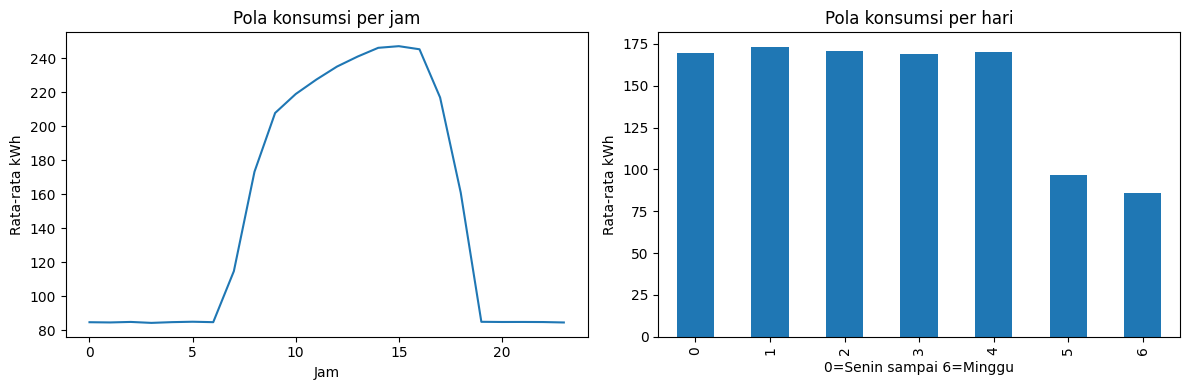

In [6]:
data_train_eda = data_bersih.loc[:"2026-02-28 23:00"]
display(data_train_eda.describe().round(2))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
data_train_eda.groupby(data_train_eda.index.hour)["konsumsi_kWh"].mean().plot(ax=ax[0])
data_train_eda.groupby(data_train_eda.index.dayofweek)["konsumsi_kWh"].mean().plot.bar(ax=ax[1])
ax[0].set(title="Pola konsumsi per jam", xlabel="Jam", ylabel="Rata-rata kWh")
ax[1].set(title="Pola konsumsi per hari", xlabel="0=Senin sampai 6=Minggu", ylabel="Rata-rata kWh")
plt.tight_layout()
plt.show()


## 4. Membuat fitur

In [7]:
def buat_fitur(tabel):
    fitur = pd.DataFrame(index=tabel.index)
    fitur["jam"] = tabel.index.hour
    fitur["hari"] = tabel.index.dayofweek
    fitur["bulan"] = tabel.index.month
    fitur["hari_libur"] = tabel["hari_libur"]
    # Proksi prakiraan memakai minggu lalu, bukan pengukuran besok.
    fitur["suhu_prakiraan"] = tabel["suhu_luar_C"].shift(168)
    fitur["okupansi_jadwal"] = tabel["okupansi_orang"].shift(168)
    for lag in [24, 48, 168]:
        fitur[f"lag{lag}"] = tabel["konsumsi_kWh"].shift(lag)
    fitur["rerata24"] = tabel["konsumsi_kWh"].shift(24).rolling(24, min_periods=12).mean()
    return fitur

fitur = buat_fitur(data_bersih)
display(fitur.loc["2024-01-09"].head())


,jam,hari,bulan,hari_libur,suhu_prakiraan,okupansi_jadwal,lag24,lag48,lag168,rerata24
waktu,,,,,,,,,,
2024-01-09 00:00:00,0,1,1,0.0,22.5,0.0,82.8,88.6,84.0,86.125000
2024-01-09 01:00:00,1,1,1,0.0,21.4,0.0,79.2,80.9,94.2,86.054167
2024-01-09 02:00:00,2,1,1,0.0,21.1,0.0,93.2,88.0,87.6,86.270833
2024-01-09 03:00:00,3,1,1,0.0,20.7,0.0,77.0,82.9,81.4,86.025000
2024-01-09 04:00:00,4,1,1,0.0,20.6,0.0,80.9,92.5,75.7,85.541667


## 5. Membagi train dan validation berdasarkan waktu

In [8]:
target = data_bersih["konsumsi_kWh"]
mask_train = (data_bersih.index >= "2024-01-09") & (data_bersih.index < "2026-03-01") & target.notna()
mask_valid = (data_bersih.index >= "2026-03-01") & target.notna() & fitur["lag168"].notna()
X_train, y_train = fitur.loc[mask_train], target.loc[mask_train]
X_valid, y_valid = fitur.loc[mask_valid], target.loc[mask_valid]
print("Baris train:", len(X_train), "| Validation berpasangan:", len(X_valid))


Baris train: 18621 | Validation berpasangan: 1441


## 6. Menghitung baseline

In [9]:
mae_baseline_valid = mean_absolute_error(y_valid, X_valid["lag168"])
print("MAE baseline validation:", mae_baseline_valid)


MAE baseline validation: 22.810825815405963


## 7. Melatih tiga kandidat model

In [10]:
model_ridge = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10))
nama_model = ["Ridge", "HistGB_15", "HistGB_31"]
daftar_model = [model_ridge]
# Dua kandidat pohon memakai pengaturan sama, kecuali jumlah daun.
for daun in [15, 31]:
    regressor = HistGradientBoostingRegressor(
        max_iter=200, max_leaf_nodes=daun, l2_regularization=10,
        early_stopping=False, random_state=18
    )
    daftar_model.append(make_pipeline(SimpleImputer(strategy="median"), regressor))

daftar_mae = []
for model in daftar_model:
    model.fit(X_train, y_train)
    prediksi_valid = model.predict(X_valid).clip(min=0)
    daftar_mae.append(mean_absolute_error(y_valid, prediksi_valid))
display(pd.DataFrame({"Model": nama_model, "MAE validation": daftar_mae}))
print("MAE baseline:", mae_baseline_valid)


,Model,MAE validation
0,Ridge,24.099950
1,HistGB_15,10.316840
2,HistGB_31,10.494026


MAE baseline: 22.810825815405963


## 8. Memilih model dan memeriksa pentingnya fitur

In [11]:
indeks_terbaik = daftar_mae.index(min(daftar_mae))
model_terbaik = daftar_model[indeks_terbaik]
nama_terbaik = nama_model[indeks_terbaik]
print("Model terpilih:", nama_terbaik)
importance = permutation_importance(
    model_terbaik, X_valid, y_valid, n_repeats=3,
    random_state=18, scoring="neg_mean_absolute_error"
)
display(pd.Series(importance.importances_mean, index=X_valid.columns).sort_values(ascending=False))


Model terpilih: HistGB_15


,0
lag168,29.070309
okupansi_jadwal,20.158571
lag24,19.142447
hari,13.221298
jam,9.292464
hari_libur,9.162110
lag48,2.434978
suhu_prakiraan,0.389329
rerata24,0.195215
bulan,-0.001364


## 9. Melatih ulang model pilihan

In [12]:
mask_final = (data_bersih.index >= "2024-01-09") & target.notna()
model_terbaik.fit(fitur.loc[mask_final], target.loc[mask_final])
joblib.dump(model_terbaik, "model_energi_sederhana.joblib")
print("Model final selesai dilatih.")


Model final selesai dilatih.


## 10. Evaluasi pada test

In [13]:
data_semua_bersih = bersihkan_data(pd.concat([data_pengembangan, data_test_mentah]))
fitur_semua = buat_fitur(data_semua_bersih)
mask_periode_test = (data_semua_bersih.index >= "2026-05-01") & (data_semua_bersih.index < "2026-07-01")
mask_test_semua = mask_periode_test & data_semua_bersih["konsumsi_kWh"].notna()
# Bandingkan model dan baseline pada jam yang sama.
mask_test = mask_test_semua & fitur_semua["lag168"].notna()
X_test = fitur_semua.loc[mask_test]
y_test = data_semua_bersih.loc[mask_test, "konsumsi_kWh"]
prediksi_test = model_terbaik.predict(X_test).clip(min=0)
baseline_test = X_test["lag168"]
mae_model = mean_absolute_error(y_test, prediksi_test)
mae_baseline = mean_absolute_error(y_test, baseline_test)
print("Jam test:", mask_periode_test.sum(), "| Jam dibandingkan:", len(y_test))
print("MAE model:", mae_model, "| MAE baseline:", mae_baseline)
if mae_baseline > 0:
    print("Penurunan MAE (%):", (1 - mae_model / mae_baseline) * 100)

prediksi_semua = model_terbaik.predict(fitur_semua.loc[mask_test_semua]).clip(min=0)
mae_semua = mean_absolute_error(data_semua_bersih.loc[mask_test_semua, "konsumsi_kWh"], prediksi_semua)
print("MAE model pada semua target test valid:", mae_semua)


Jam test: 1464 | Jam dibandingkan: 1440
MAE model: 10.053168802307884 | MAE baseline: 24.825277777777778
Penurunan MAE (%): 59.50430487707603
MAE model pada semua target test valid: 10.242916396708221


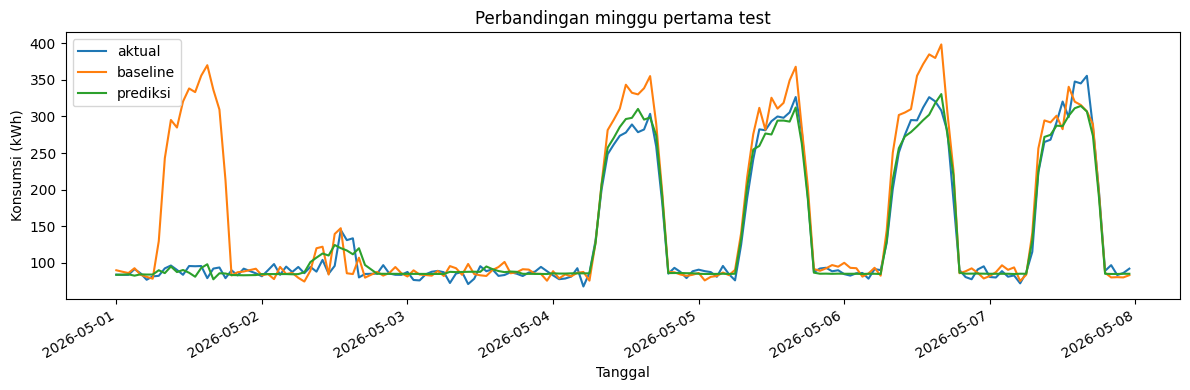

In [14]:
hasil_test = pd.DataFrame({"aktual": y_test, "baseline": baseline_test, "prediksi": prediksi_test})
hasil_test.to_csv("hasil_prediksi_test.csv")
ax = hasil_test.loc["2026-05-01":"2026-05-07"].plot(figsize=(12, 4))
ax.set(xlabel="Tanggal", ylabel="Konsumsi (kWh)", title="Perbandingan minggu pertama test")
plt.tight_layout()
plt.savefig("grafik_hasil_test.png", dpi=160)
plt.show()


## 11. Demo prediksi 24 jam untuk 1 Juli 2026

In [17]:
tanggal_prediksi = pd.Timestamp("2026-07-01")
riwayat = data_semua_bersih.loc[data_semua_bersih.index < tanggal_prediksi].tail(240)
assert riwayat.index.max() == tanggal_prediksi - pd.Timedelta(hours=1), "Riwayat harus berakhir sehari sebelumnya pukul 23.00"
jam_prediksi = pd.date_range(tanggal_prediksi, periods=24, freq="h")
data_demo = riwayat.reindex(pd.date_range(riwayat.index.min(), jam_prediksi[-1], freq="h"))
data_demo.loc[jam_prediksi, "hari_libur"] = 0
X_besok = buat_fitur(data_demo).loc[jam_prediksi].copy()

# Nilai pengganti khusus demo, mengikuti contoh proyek sebelumnya.
X_besok = X_besok.fillna({"suhu_prakiraan": 25, "okupansi_jadwal": 0})
assert X_besok[["lag24", "lag48", "lag168"]].notna().sum().sum() >= 36, "Riwayat konsumsi terlalu banyak kosong"
prediksi_besok = model_terbaik.predict(X_besok).clip(min=0)
hasil_besok = pd.DataFrame({"waktu": jam_prediksi, "prediksi_kWh": prediksi_besok})
display(hasil_besok)
print("Total prediksi energi:", round(hasil_besok["prediksi_kWh"].sum(), 2), "kWh")
hasil_besok.to_csv("prediksi_1_Juli_2026.csv", index=False)


,waktu,prediksi_kWh
0,2026-07-01 00:00:00,84.896088
1,2026-07-01 01:00:00,84.896088
2,2026-07-01 02:00:00,84.858661
3,2026-07-01 03:00:00,84.896088
4,2026-07-01 04:00:00,84.563290
5,2026-07-01 05:00:00,84.563290
6,2026-07-01 06:00:00,84.896088
7,2026-07-01 07:00:00,133.535755
8,2026-07-01 08:00:00,215.377488
9,2026-07-01 09:00:00,273.529077


Total prediksi energi: 4332.09 kWh


## 12. Menyimpan Model

In [18]:
import json
import joblib
import sklearn
import zipfile
from google.colab import files

# 1. Simpan model final beserta preprocessing-nya
joblib.dump(model_terbaik, "model.joblib")

# 2. Simpan feature importance dari hasil validation
feature_importance = pd.DataFrame({
    "feature": X_valid.columns,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std
})

feature_importance = feature_importance.sort_values(
    "importance_mean", ascending=False
)
feature_importance.to_csv("feature_importance.csv", index=False)

# 3. Buat metadata untuk mendokumentasikan model
metadata = {
    "model": nama_terbaik,
    "target": "konsumsi_kWh",
    "features": X_train.columns.tolist(),
    "model_parameters": model_terbaik.steps[-1][1].get_params(),
    "preprocessing": "SimpleImputer dengan median",
    "prediction_postprocessing": "clip(min=0)",
    "validation_mae": dict(zip(nama_model, daftar_mae)),
    "baseline_validation_mae": float(mae_baseline_valid),
    "test_mae": float(mae_model),
    "baseline_test_mae": float(mae_baseline),
    "train_rows": len(X_train),
    "validation_rows": len(X_valid),
    "final_training_rows": int(mask_final.sum()),
    "test_rows": len(X_test),
    "split": {
        "train": "2024-01-09 sampai 2026-02-28",
        "validation": "2026-03-01 sampai 2026-04-30",
        "test": "2026-05-01 sampai 2026-06-30"
    },
    "feature_importance": {
        "method": "permutation_importance",
        "data": "validation sebelum pelatihan ulang",
        "scoring": "neg_mean_absolute_error",
        "n_repeats": 3,
        "random_state": 18
    },
    "versions": {
        "sklearn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "joblib": joblib.__version__
    }
}

with open("metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, ensure_ascii=False)

# 4. Gabungkan ketiga file ke ZIP dan unduh
nama_file = ["model.joblib", "metadata.json", "feature_importance.csv"]

with zipfile.ZipFile("artifacts_energi.zip", "w", zipfile.ZIP_DEFLATED) as zip_file:
    for nama in nama_file:
        zip_file.write(nama)

files.download("artifacts_energi.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>